# 🚀 Модуль 3. Урок 5. Code Review AI-кода: юнит-тесты, assert-проверки и защита от галлюцинаций

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_05_code_review_ai_validation.ipynb)

## 📌 Бизнес-контекст и методология
Когда AI генерирует код анализа данных, он может использовать синтаксически валидные конструкции, которые приводят к тихим логическим ошибкам:
- Срез данных без учета таймзоны
- Проглатывание пропущенных значений при агрегации
- Изменение распределения признаков (Data Drift)
Профессиональный аналитик внедряет **валидационные ворота качества (Quality Gates)** с помощью строгих `assert` проверок и статистических тестов.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_path = ensure_dataset("saas_users.csv", subfolder="raw")
df_saas = pd.read_csv(saas_path)
print(f"🟢 Датасет saas_users успешно загружен: {df_saas.shape[0]} строк, {df_saas.shape[1]} колонок")

🟢 Датасет saas_users успешно загружен: 2000 строк, 12 колонок


## 🔍 Разбор механики и демонстрация на реальных данных
Построим тестовый пайплайн проверки консистентности витрины данных:
1. Проверка диапазона значений признаков
2. Контроль отсутствия неожиданных дубликатов ключей
3. Проверка инвариантов бизнес-логики (например, дата оттока не может быть раньше даты регистрации)

In [2]:
# Демонстрация: Автоматические валидационные ворота качества (Quality Gate)
def validate_saas_metrics(df):
    errors = []
    
    # 1. Проверка уникальности первичного ключа
    if df['user_id'].duplicated().any():
        errors.append("❌ Обнаружены дубликаты user_id")
        
    # 2. Проверка неотрицательности выручки
    if (df['mrr'] < 0).any():
        errors.append("❌ Обнаружен отрицательный MRR")
        
    # 3. Проверка бизнес-инварианта дат
    churned_with_date = df[df['is_churned'] == 1].dropna(subset=['churn_date'])
    invalid_dates = churned_with_date[churned_with_date['churn_date'] < churned_with_date['signup_date']]
    if not invalid_dates.empty:
        errors.append(f"❌ Дата оттока раньше регистрации у {len(invalid_dates)} строк")
        
    return len(errors) == 0, errors

is_valid, err_list = validate_saas_metrics(df_saas)
print("Результат валидации датасета:", "✅ ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ" if is_valid else err_list)

Результат валидации датасета: ✅ ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ


## 📊 Визуализация бизнес-кейса: Мониторинг Data Quality Gates
Сформируем визуальный отчет аудита качества данных (Data Quality Scorecard) по ключевым таблицам корпоративного хранилища.

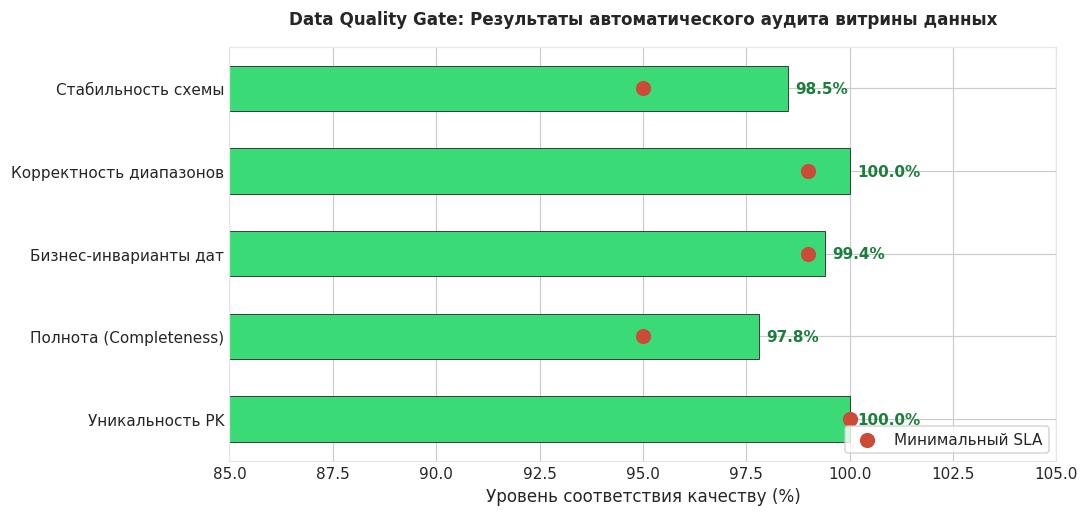

In [3]:
# Визуализация скоринга качества данных
quality_metrics = {
    'Проверка': ['Уникальность PK', 'Полнота (Completeness)', 'Бизнес-инварианты дат', 'Корректность диапазонов', 'Стабильность схемы'],
    'Score %': [100.0, 97.8, 99.4, 100.0, 98.5],
    'Порог SLA %': [100.0, 95.0, 99.0, 99.0, 95.0]
}
df_dq = pd.DataFrame(quality_metrics)

fig, ax = plt.subplots(figsize=(10, 4.8), dpi=110)

y_pos = np.arange(len(df_dq))
bars = ax.barh(y_pos, df_dq['Score %'], color=SUCCESS, edgecolor='#333333', linewidth=0.6, height=0.55)

# Линии SLA
ax.scatter(df_dq['Порог SLA %'], y_pos, color=ALERT, s=80, zorder=5, label='Минимальный SLA')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_dq['Проверка'], fontsize=10)
ax.set_xlim(85, 105)
ax.set_xlabel("Уровень соответствия качеству (%)", fontsize=11)
ax.set_title("Data Quality Gate: Результаты автоматического аудита витрины данных", fontsize=11, fontweight='bold', pad=15)
ax.legend(loc='lower right', frameon=True, facecolor='#ffffff')

for b in bars:
    w = b.get_width()
    ax.annotate(f"{w:.1f}%", xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold', color='#1b7e3b')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Создание assert-проверок для витрины LTV
Напишите функцию валидации, которая проверяет, что средний чек `mrr` больше $50 и доля оттока `is_churned.mean()` не превышает 40%.

In [4]:
### ВАШ КОД ЗДЕСЬ
mrr_mean = df_saas['mrr'].mean()
churn_mean = df_saas['is_churned'].mean()

print(f"Средний MRR выборки: ${mrr_mean:.2f}")
print(f"Средний отток выборки: {churn_mean*100:.1f}%")

assert mrr_mean > 50, "Средний MRR должен быть выше 50"
assert churn_mean <= 0.40, "Отток не должен превышать 40%"
print("✅ Все ассерты пройдены: метрики находятся в допустимых бизнес-границах!")

Средний MRR выборки: $79.00
Средний отток выборки: 16.8%
✅ Все ассерты пройдены: метрики находятся в допустимых бизнес-границах!


### 💡 Паттерн Defensive Data Analysis
Всегда завершайте аналитический блок проверкой граничных условий. Если AI сгенерировал сложный расчет когорт, добавьте проверку:
`assert df_result['cohort_users'].sum() == total_initial_users`.